## Subsudence time analysis


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import contextily as ctx
import folium
from folium.plugins import Fullscreen
import branca.colormap as cm




In [2]:
# Load raw data
raw_df = pd.read_excel('insar_sinkholes.xlsx', sheet_name='sheet1', header=None)
columns = raw_df.iloc[1, 1:7].values

In [3]:
# Create a copy of Oren's data
oren_df = raw_df.iloc[2:25, 1:7].copy()
oren_df.columns = columns
oren_df['source'] = "Oren's Sinkholes"

In [4]:
# Create a copy of Gidi's data
gidi_df = raw_df.iloc[26:64, 1:7].copy()
gidi_df.columns = columns
gidi_df['source'] = "Gidi's Sinkholes"

In [5]:
def date_range_midpoint(date_range):
    """
    Calculate the midpoint of a date range in the format 'dd/mm/yyyy - dd/mm/yyyy'.
    Args:
        date_range (str): A string representing the date range.
    Returns:
        pd.Timestamp: The midpoint date as a pandas Timestamp, or pd.NaT if the input
    """
    if pd.isna(date_range) or not isinstance(date_range, str):
        return pd.NaT
    dates = date_range.split('-')
    if len(dates) != 2:
        return pd.NaT
    try:
        start_date = pd.to_datetime(dates[0], format='%d/%m/%Y', errors='coerce')
        end_date = pd.to_datetime(dates[1], format='%d/%m/%Y', errors='coerce')
        midpoint = start_date + (end_date - start_date) / 2
        return midpoint
    except Exception:
        return pd.NaT

In [6]:
# Calculate the tamespan between sink and collapse dates for Oren's data
oren_df['sink_mid'] = oren_df['Sink date'].apply(date_range_midpoint)
oren_df['collapse_mid'] = oren_df['Collapse date'].apply(date_range_midpoint)
oren_df['diff_days'] = (oren_df['collapse_mid'] - oren_df['sink_mid']).dt.days

In [7]:
# Calculate the tamespan between sink and collapse dates for Gidi's data
gidi_df['sink_mid'] = pd.to_datetime(gidi_df['Sink date'])
gidi_df['collapse_mid'] = pd.to_datetime(gidi_df['Collapse date'])
gidi_df['diff_days'] = (gidi_df['collapse_mid'] - gidi_df['sink_mid']).dt.days

In [8]:
# Combine the two dataframes into one
combined_df = pd.concat([oren_df, gidi_df], ignore_index=True)

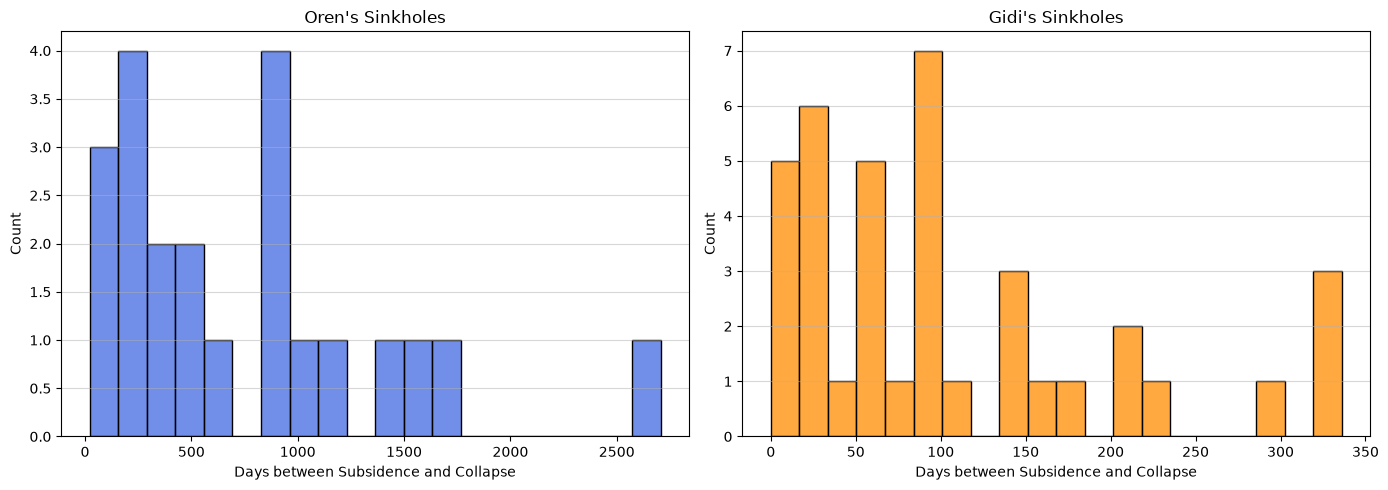

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

# Plot histograms for Oren's dataset
sns.histplot(data=oren_df, x='diff_days', bins=20, ax=axes[0], color='royalblue')
axes[0].set_title('Oren\'s Sinkholes')
axes[0].set_xlabel('Days between Subsidence and Collapse')
axes[0].set_ylabel('Count')
axes[0].grid(axis='y', alpha=0.5)

# Plot histograms for Gidi's dataset
sns.histplot(data=gidi_df, x='diff_days', bins=20, ax=axes[1], color='darkorange')
axes[1].set_title("Gidi's Sinkholes")
axes[1].set_xlabel('Days between Subsidence and Collapse')
axes[1].set_ylabel('Count')
axes[1].grid(axis='y', alpha=0.5)

plt.tight_layout()
plt.show()

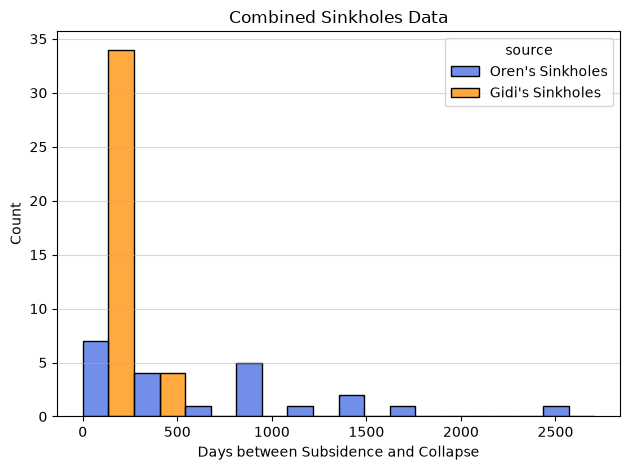

In [10]:
sns.histplot(data=combined_df, x='diff_days', bins=10, hue='source', multiple='dodge', palette=['royalblue', 'darkorange'])
plt.title('Combined Sinkholes Data')
plt.xlabel('Days between Subsidence and Collapse')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

In [11]:
combined_df['Latitude'] = pd.to_numeric(combined_df['Latitude'], errors='coerce')
combined_df['Longitude'] = pd.to_numeric(combined_df['Longitude'], errors='coerce')

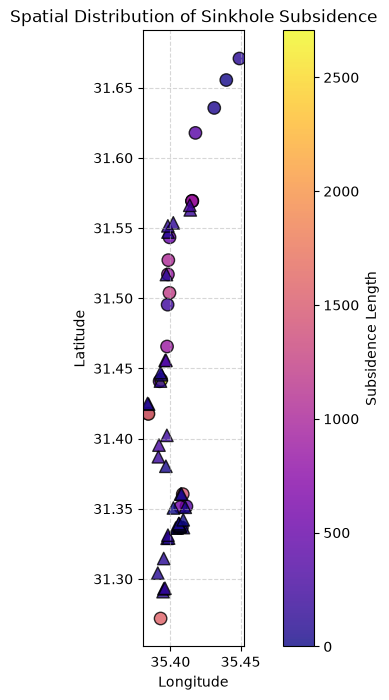

In [18]:
markers = {
    "Oren's Sinkholes": 'o', 
    "Gidi's Sinkholes": '^'
}

vmin = combined_df['diff_days'].min()
vmax = combined_df['diff_days'].max()

plt.figure(figsize=(10, 8))

for source, marker in markers.items():
    subset = combined_df[combined_df['source'] == source]


    scatter = plt.scatter(
        x=subset['Longitude'], 
        y=subset['Latitude'], 
        c=subset['diff_days'],
        marker=marker,
        cmap='plasma',
        vmin=vmin,
        vmax=vmax,
        s=80,
        edgecolor='black',
        alpha=0.8
    )



cbar = plt.colorbar(scatter)
cbar.set_label('Subsidence Length')

plt.title('Spatial Distribution of Sinkhole Subsidence')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.gca().set_aspect('equal')
plt.show()

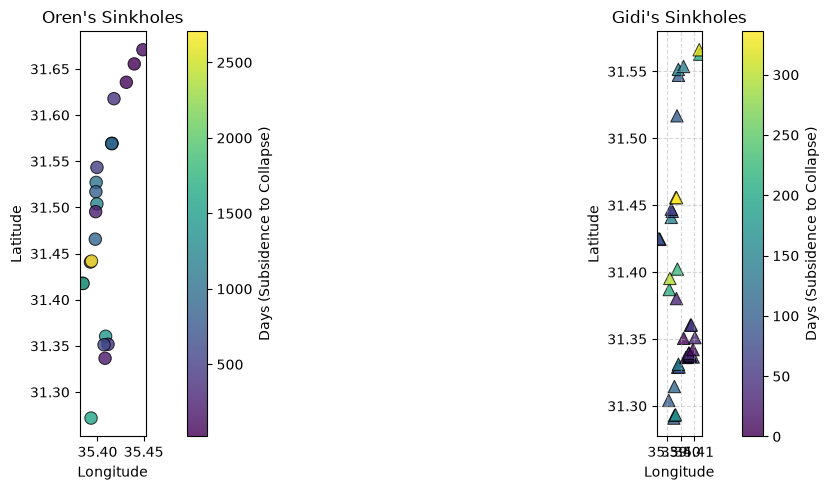

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
    
sns.scatterplot(
    x=oren_df['Longitude'], 
    y=oren_df['Latitude'], 
    c=oren_df['diff_days'],
    marker='o',
    cmap='viridis',
    s=80,
    edgecolor='black',
    alpha=0.8,
    ax=axes[0]
)

sns.scatterplot(
    x=gidi_df['Longitude'], 
    y=gidi_df['Latitude'], 
    c=gidi_df['diff_days'],
    marker='^',
    cmap='viridis',
    s=80,
    edgecolor='black',
    alpha=0.8,
    ax=axes[1]
)

axes[0].set_aspect('equal')
axes[1].set_aspect('equal')

axes[0].set_title('Oren\'s Sinkholes')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(False)
cbar_oren = fig.colorbar(axes[0].collections[0], ax=axes[0])
cbar_oren.set_label('Days (Subsidence to Collapse)')



axes[1].set_title("Gidi's Sinkholes")
axes[1].set_xlabel('Longitude')
axes[1].grid(True, linestyle='--', alpha=0.5)
cbar_gidi = fig.colorbar(axes[1].collections[0], ax=axes[1])
cbar_gidi.set_label('Days (Subsidence to Collapse)')

plt.tight_layout()
plt.show()

In [14]:
min_days_oren = oren_df['diff_days'].min()
max_days_oren = oren_df['diff_days'].max()
min_days_gidi = gidi_df['diff_days'].min()
max_days_gidi = gidi_df['diff_days'].max()

# Create color maps for Oren's and Gidi's sinkholes
colormap_oren = cm.linear.plasma.scale(min_days_oren, max_days_oren)
colormap_oren.caption = 'Subsidence to Collapse Duration (Days)'

colormap_gidi = cm.linear.viridis.scale(min_days_gidi, max_days_gidi)
colormap_gidi.caption = 'Subsidence to Collapse Duration (Days)'

# Center the map around the Dead Sea area
m = folium.Map(location=[31.45, 35.40], zoom_start=11, tiles="OpenStreetMap")

# Add the color maps to the map
folium.TileLayer('Esri.WorldImagery', name='Satellite').add_to(m)

Fullscreen(
    position='topleft',
    title='Expand to Fullscreen',
    title_cancel='Exit Fullscreen',
    force_separate_button=True
).add_to(m)

# Add Oren's sinkholes to the map with circle markers
fg_oren = folium.FeatureGroup(name="Oren's Sinkholes").add_to(m)
for _, row in oren_df.dropna(subset=['Latitude', 'Longitude', 'diff_days']).iterrows():
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=6,
        color='black',
        weight=1,
        fill=True,
        fill_color=colormap_oren(row['diff_days']),
        fill_opacity=0.8,
        tooltip=f"Oren's Sinkhole | Duration: {row['diff_days']} days"
    ).add_to(fg_oren)

# Add Gidi's sinkholes to the map with triangle markers
fg_gidi = folium.FeatureGroup(name="Gidi's Sinkholes").add_to(m)
for _, row in gidi_df.dropna(subset=['Latitude', 'Longitude']).iterrows():
    folium.RegularPolygonMarker(
        location=[row['Latitude'], row['Longitude']],
        number_of_sides=3,
        radius=6,
        color='black',
        weight=1,
        fill=True,
        fill_color=colormap_gidi(row['diff_days']),
        fill_opacity=0.8,
        tooltip=f"Gidi's Sinkhole | Duration: {row['diff_days']} days"
    ).add_to(fg_gidi)

folium.LayerControl().add_to(m)
m